In [1]:
#Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Base directory for AntM2C_10M
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"

# Structured image directory (validated in 01_image_path_validation)
image_dir = f"{base_dir}/AntM2C_image_structured"

# Path to CSV containing item_id -> structured image path
image_paths_csv = f"{base_dir}/AntM2C_preprocessed/image_paths_structured.csv"

print("Image directory:", image_dir)
print("CSV path:", image_paths_csv)

Image directory: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_image_structured
CSV path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/image_paths_structured.csv


In [41]:
import os
import pandas as pd
import numpy as np
import torch
import json
import random
import umap.umap_ as umap

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModel

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## Loading Pretrained ViT Model
Model: google/vit-base-patch16-224-in21k

*   Output embedding size = 768
*   Uses AutoImageProcessor for resizing / normalization
*   Sets eval() and no_grad() for efficient inference

In [8]:
# Pretrained model name
vit_model_name = "google/vit-base-patch16-224-in21k"

# Load processor (handles resize, crop, normalization)
processor = AutoImageProcessor.from_pretrained(vit_model_name)

# Load pretrained ViT (encoder only, no classification head needed)
model = AutoModel.from_pretrained(vit_model_name)
model = model.to(device)
model.eval()

print("Loaded ViT model:", vit_model_name)

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


Loaded ViT model: google/vit-base-patch16-224-in21k


Passing a dummy image to check the output

In [ ]:
# Create a dummy batch of 1 image (random)
dummy_image = torch.rand(1, 3, 224, 224).to(device)

with torch.no_grad():
    outputs = model(pixel_values=dummy_image)
    cls_embedding = outputs.last_hidden_state[:, 0, :]

print("CLS embedding shape:", cls_embedding.shape)

CLS embedding shape: torch.Size([1, 768])


This confirms that the model is loaded correctly, and that it is configured, and the output dimensions for image will be 768-dim vectors

## Load and validate Image Metadata

In this step, we load the image_paths_structured.csv file generated during preprocessing.

*   item_id -> unique AntM2C item identifier
*   image_path -> structured folder path (e.g., 287/28721.png)

The goal is to ensure that the Vision Transformer receives only valid, aligned image paths so that the embedding matrix indexing matches the item_id list perfectly.

In [9]:
# Load metadata CSV
df = pd.read_csv(image_paths_csv)

print("Total rows in CSV:", len(df))
df.head()

Total rows in CSV: 59142


,item_id,image_path
0,28721,287/28721.png
1,287697,287/287697.png
2,287443,287/287443.png
3,28734,287/28734.png
4,287655,287/287655.png


In [14]:
# Clean and normalize image paths
df["image_path"] = (
    df["image_path"]
    .astype(str)
    .str.strip()
    .str.lstrip("/\\")
)

valid_items = []
missing_count = 0
debug_shown = 0

for _, row in tqdm(df.iterrows(), total=len(df)):
    item_id = int(row["item_id"])
    img_path = row["image_path"]

    full_path = os.path.join(image_dir, img_path)

    if not os.path.exists(full_path):
        missing_count += 1
        if debug_shown < 3:
            print("[Missing file]", full_path)
            debug_shown += 1
        continue

    valid_items.append((item_id, full_path))

print(f"Valid images found: {len(valid_items)}")
print(f"Missing images skipped: {missing_count}")

100%|██████████| 59142/59142 [02:22<00:00, 416.19it/s] 

Valid images found: 59142
Missing images skipped: 0


## Fast Image Preprocessing + Streaming Batching


In this step, we prepare all images for the Vision Transformer (ViT). Although ViT uses its own preprocessing pipeline via AutoImageProcessor, we still need a reliable method to load images ffrom the disk, apply preprocessing, batch images, skip corrupted images and prepare batched for feature extractions.

This optimized version uses:
*   PyTorch Dataset for efficient loading
*   ImageProcessor for on-the-fly ViT preprocessing
*   DataLoader with 4 workers for parallel I/O
*   Streaming batches directly into ViT

In [17]:
class AntM2CImageDataset(Dataset):
    def __init__(self, items, processor):
        self.items = items
        self.processor = processor

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item_id, img_path = self.items[idx]

        try:
            img = Image.open(img_path).convert("RGB")
            pixel = self.processor(img, return_tensors="pt")["pixel_values"][0]
            return item_id, pixel
        except:
            return None  # skip corrupted images

Data Loader (Parellel loading)

In [18]:
dataset = AntM2CImageDataset(valid_items, processor)

loader = DataLoader(
    dataset,
    batch_size=64,
    num_workers=4,
    pin_memory=True,
    shuffle=False,
    collate_fn=lambda x: [i for i in x if i is not None]
)

print("Total images:", len(dataset))

Total images: 59142


## ViT Embedding Extraction

In [19]:
all_embeddings = []
all_item_ids = []

model.eval()

with torch.no_grad():
    for batch in tqdm(loader):
        ids = []
        pixels = []

        for item_id, pixel in batch:
            ids.append(item_id)
            pixels.append(pixel)

        pixels = torch.stack(pixels).to(device)  # Move to GPU

        # Forward pass through ViT
        outputs = model(pixel_values=pixels)
        cls_embeds = outputs.last_hidden_state[:, 0, :].cpu()  # (B, 768)

        all_embeddings.append(cls_embeds)
        all_item_ids.extend(ids)

# Concatenate everything
all_embeddings = torch.cat(all_embeddings, dim=0)

100%|██████████| 925/925 [1:57:58<00:00,  7.65s/it]


##Saving the Embedding Matrix

In this step, we save the extracted image embeddings and the corresponding item_id mapping.
Since the Vision Transformer returns a 768-dimensional embedding for each image, and batches are processed in a streamed manner, we concatenate them into a final 2D tensor with shape of ***(num_images, 768)***

We then store:
*   The embedding matrix as a PyTorch .pt file (more efficient than .npy)
*   The ordered list of item_ids as a JSON file, ensuring exact alignment (row i in the embedding matrix corresponds to item_id[i])



In [27]:
# Save embeddings (.pt)
emb_path = f"{base_dir}/image_embeddings_vit_base.pt"
torch.save(all_embeddings, emb_path)

# Save item_id → index mapping (JSON)
id_path = f"{base_dir}/item_id_to_index.json"
with open(id_path, "w") as f:
    json.dump(all_item_ids, f)

print("Saved embeddings to:", emb_path)
print("Saved mapping to:", id_path)

Saved embeddings to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/image_embeddings_vit_base.pt
Saved mapping to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/item_id_to_index.json


## Visualizations & Sanity Checks and Summary

In [28]:
print("Embedding Tensor Shape:", all_embeddings.shape)

Embedding Tensor Shape: torch.Size([59140, 768])


In [31]:
# Check alignment between item_ids and embeddings
assert len(all_item_ids) == all_embeddings.shape[0], "Mismatch! Item ID count != embedding rows"
print("Alignment OK:", len(all_item_ids), "item_ids aligned with embeddings.")

Alignment OK: 59140 item_ids aligned with embeddings.


In [32]:
# Check for NaNs or infinite values
print("NaNs in embeddings:", torch.isnan(all_embeddings).sum().item())
print("Infs in embeddings:", torch.isinf(all_embeddings).sum().item())

NaNs in embeddings: 0
Infs in embeddings: 0


In [34]:
# Sample entry
sample_idx = np.random.randint(0, all_embeddings.shape[0])
print("Random sample index:", sample_idx)
print("Item ID:", all_item_ids[sample_idx])
print("Embedding vector (first 10 dims):", all_embeddings[sample_idx][:10])

Random sample index: 46657
Item ID: 688901
Embedding vector (first 10 dims): tensor([ 6.3700e-02, -2.1157e-01,  8.1675e-02, -1.9570e-05,  5.8099e-02,
         1.4207e-01, -4.4727e-01,  4.9660e-02, -5.2280e-02, -1.2892e-02])


#### Embedding norm analysis
We visualize the L2-norm distribution of embeddings to confirm they fall in a reasonable range and do not contain outliers or collapsed vectors.

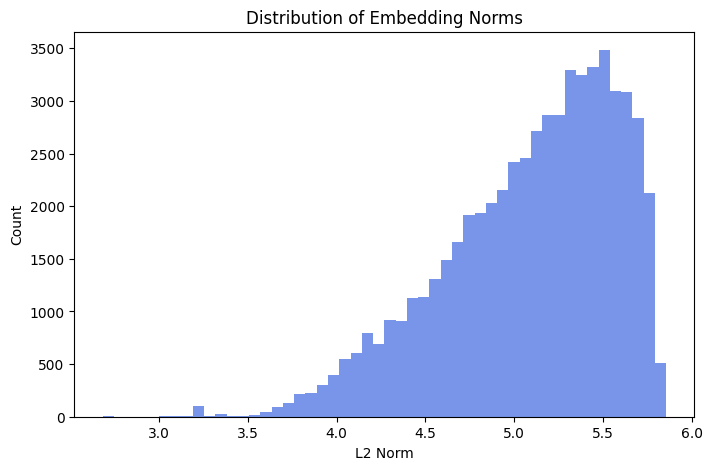

Mean norm: 5.0931606
Std norm: 0.4872858


In [35]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Reload
# all_embeddings = torch.load(f"{base_dir}/image_embeddings_vit_base.pt")

# Compute norms
embedding_norms = torch.norm(all_embeddings, dim=1).cpu().numpy()

plt.figure(figsize=(8,5))
plt.hist(embedding_norms, bins=50, color='royalblue', alpha=0.7)
plt.title("Distribution of Embedding Norms")
plt.xlabel("L2 Norm")
plt.ylabel("Count")
plt.show()

print("Mean norm:", np.mean(embedding_norms))
print("Std norm:", np.std(embedding_norms))

This indicates that the model is operating in a healthy range—
there are no collapsed vectors (very low norms), no exploding activations (very high norms), and no NaN/Inf values.
The narrow variance also suggests consistent feature extraction across diverse ad images.

#### Image -> Embedding norm pairs
We display a few sample images alongside their embedding norms to observe whether visually complex images correspond to higher/lower activation magnitudes.

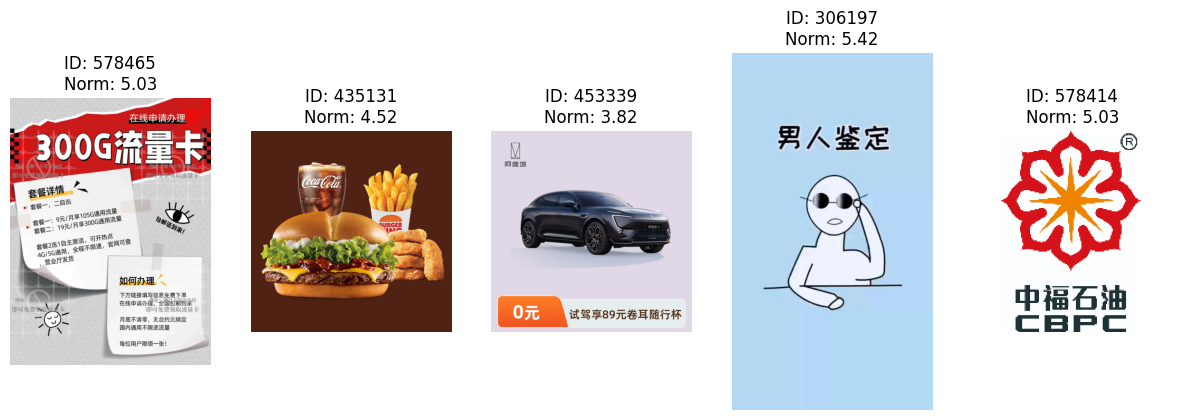

In [37]:
# Choose 5 random indices
idxs = random.sample(range(len(all_item_ids)), 5)

plt.figure(figsize=(15,8))

for i, idx in enumerate(idxs):
    item_id = all_item_ids[idx]
    img_path = dict(valid_items)[item_id]  # convert list of tuples -> dict lookup

    img = Image.open(img_path).convert("RGB")
    norm = embedding_norms[idx]

    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.title(f"ID: {item_id}\nNorm: {norm:.2f}")
    plt.axis("off")

plt.show()

A random set of images showed norm values between ~3.8 and ~5.4, corresponding to:
*   Higher-text or more visually dense ads -> slightly higher norms
*   Cleaner / simpler images -> slightly lower norms

This behaviour is expected for ViT models and suggests that embedding magnitude reflects visual content complexity, not noise.

#### PCA/UMAP projections
We reduce a random subset of embeddings (e.g., 1,000 points) into 2D using PCA or UMAP, giving us a quick look at cluster structure.

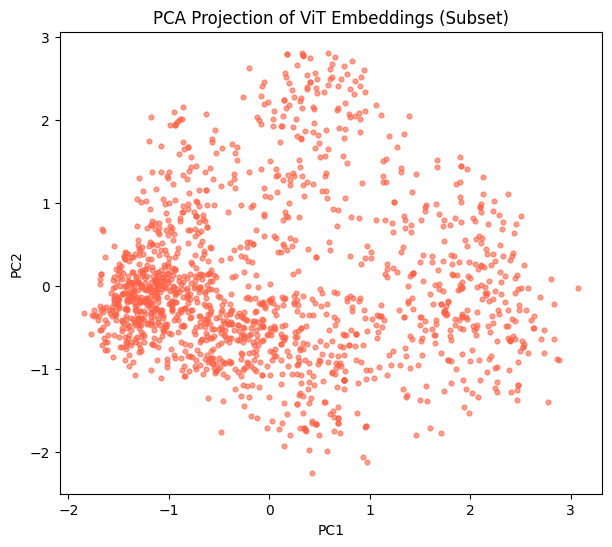

In [39]:
# Take a subset of 1500 embeddings to reduce compute
subset_idx = np.random.choice(len(all_embeddings), size=1500, replace=False)
subset_emb = all_embeddings[subset_idx].numpy()

pca = PCA(n_components=2)
pca_result = pca.fit_transform(subset_emb)

plt.figure(figsize=(7,6))
plt.scatter(pca_result[:,0], pca_result[:,1], s=12, alpha=0.6, c='tomato')
plt.title("PCA Projection of ViT Embeddings (Subset)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

The PCA plot (subset of 1500 embeddings) forms:
*   A coherent cloud with visible sub-clusters
*   No severe outliers
*   Smooth transitions between clusters

This indicates the embeddings lie on a low-dimensional manifold and contain meaningful structure suitable for downstream fusion (e.g., MMoE, meta-embeddings).

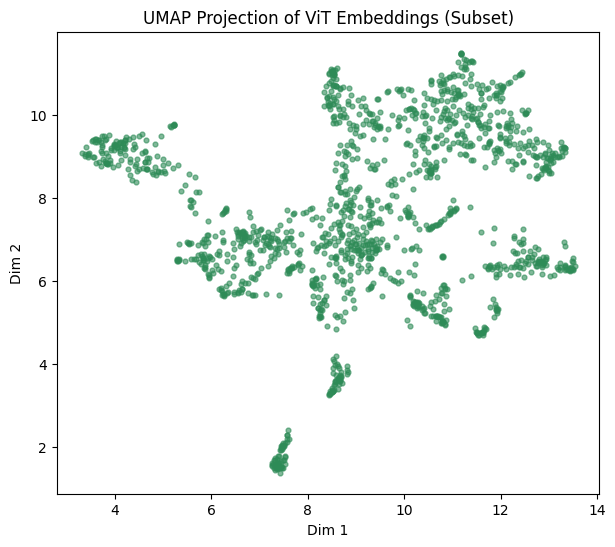

In [43]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='euclidean')

umap_result = reducer.fit_transform(subset_emb)

plt.figure(figsize=(7,6))
plt.scatter(umap_result[:,0], umap_result[:,1], s=12, alpha=0.6, c='seagreen')
plt.title("UMAP Projection of ViT Embeddings (Subset)")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

UMAP reveals:
*   Well-defined, dense clusters
*   Sub-groups reflecting similarity in product imagery
*   Clear separation between visually distinct categories

UMAP reinforces that ViT embeddings capture semantic relationships, even though labels are not used.